In [1]:
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#Carregar o modelo
from keras.models import load_model
#salvar/carregar arquivos em diferentes formatos
import joblib
# manipulação de arquivos e diretórios
import os

2026-10-17 11:10:56.163487: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-17 11:10:56.165312: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-17 11:10:56.199560: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-17 11:10:56.200718: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

In [2]:
os.listdir()

['10-Modelo_regressão_contraste_10-09-24 copy.ipynb',
 '10-Modelo_regressão_contraste_10-09-24.ipynb',
 '11-Correlação_validação_campo_claro_plasmodium_16-09-24.ipynb',
 '12-Ampliação do banco imagens fluorescencia-27-09-24.ipynb',
 '13-Modelo_regressão_fluorescente_22-08-24.ipynb',
 '14-Correlação_validação_campo_fluorescente_plasmodium_30-09-24.ipynb',
 '15-Correlação transfecção Julia.ipynb',
 '16-crossvalidation_Modelo_regressão_contraste_10_03_25.ipynb',
 '17-ampliação_img_predição_campo_claro_11_02_25.ipynb',
 '18-predição_novas_img_BAELB_campo_claro_plasmodium_11_02_25.ipynb',
 '19-ampliação_img_predição_campo_fluorescente_11_02_25',
 '1_Retirada_excesso_pixel_2026-10-09.ipynb',
 '20-predição_novas_img_BAELB_campo_fluo_plasmodium_11_02_25.ipynb',
 '21-ampliação_img_predição_HBMEC_realce_01-07-25',
 '22-predição_novas_img_HBMEC_11_06_25.ipynb',
 '23-ampliação_img_predição_HUVEC_realce_16-07-25',
 '24-predição_novas_img_HUVEC_11_06_25.ipynb',
 '25-Modelo_regressão_HBMEC_13-11-25.i

In [3]:
#Importando o modelo contendo os valores previstos para o número de células nas imagens
# modelo_maior_erro = load_model('/content/drive/MyDrive/teste/imagens_julia_quantificacao/lista de imagens e rótulos - contraste digital/img_e_rot_para_validação_contraste/modelo_fluore_100_75_50_25_2024-9-10.keras')

diretorio = "./data/imagens de contraste de fase (CHO745)/"

modelo_maior_erro = load_model( f'{diretorio}modelo_fluore_100_75_50_25_2026-10-16.keras')
modelo_maior_erro

In [4]:
# X_test_maior_erro = joblib.load('/content/drive/MyDrive/teste/imagens_julia_quantificacao/lista de imagens e rótulos - contraste digital/img_e_rot_para_validação_contraste/imagens_validação_10%_fluore_2024-9-10.gz') #carregando arquivo
X_test_maior_erro = joblib.load(f'{diretorio}imagens_validacao_10%_fluore_2026-10-16.gz') #carregando arquivo
X_test_maior_erro.shape

(63, 300, 300, 3)

In [5]:
# y_test_maior_erro = joblib.load('/content/drive/MyDrive/teste/imagens_julia_quantificacao/lista de imagens e rótulos - contraste digital/img_e_rot_para_validação_contraste/rótulos_validação_10%_fluore_2024-9-10.gz') #carregando arquivo
y_test_maior_erro = joblib.load(f'{diretorio}rótulos_validacao_10%_fluore_2026-10-16.gz') #carregando arquivo
y_test_maior_erro.shape

(63,)

In [6]:
#ROTULOS SALVOS EM LISTA

lista_observado_maior_erro = list(y_test_maior_erro)
len(lista_observado_maior_erro)

63

In [7]:
#PREDIÇÃO SALVO EM LISTA

dados_prev = modelo_maior_erro.predict(X_test_maior_erro)
lista_previsto_maior_erro = dados_prev.flatten().tolist()
len(lista_previsto_maior_erro)

2/2 [==============================] - 1s 269ms/step


63

In [8]:
import pandas as pd
from scipy.stats.stats import pearsonr as stats

/tmp/ipykernel_8307/3864774765.py:2: DeprecationWarning: Please use `pearsonr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import pearsonr as stats


In [9]:
#DATAFRAME - ORGANIZAÇÃO DAS LISTAS
#COLUNA 1 ROTULO/ COLUNA 2 PREDITO

df_maior_erro = pd.DataFrame(zip(lista_observado_maior_erro,lista_previsto_maior_erro),
                             columns = ['Observed values','Lista preditos'])
df_maior_erro.head()

,Observed values,Lista preditos
0,483,411.926575
1,195,274.359802
2,285,254.903320
3,275,213.096832
4,648,601.374451


In [10]:
#ARREDONDANDO O PREDITO ('lista preditos')

teste = round(df_maior_erro['Lista preditos'],2)
df_maior_erro['Predicted values'] = teste
df_maior_erro.head()

,Observed values,Lista preditos,Predicted values
0,483,411.926575,411.93
1,195,274.359802,274.36
2,285,254.903320,254.90
3,275,213.096832,213.10
4,648,601.374451,601.37


In [11]:
#REORGANIZANDO AS COLUNAS

df_maior_erro = df_maior_erro.reindex(columns=['Observed values','Predicted values','Lista preditos'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos
0,483,411.93,411.926575
1,195,274.36,274.359802
2,285,254.90,254.903320
3,275,213.10,213.096832
4,648,601.37,601.374451


In [12]:
#BIBLIOTECA CORRELAÇÃO
from scipy.stats.stats import spearmanr, pearsonr #importando a biblioteca para gráfico de correlação

/tmp/ipykernel_8307/3800669654.py:2: DeprecationWarning: Please use `spearmanr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import spearmanr, pearsonr #importando a biblioteca para gráfico de correlação
/tmp/ipykernel_8307/3800669654.py:2: DeprecationWarning: Please use `pearsonr` from the `scipy.stats` namespace, the `scipy.stats.stats` namespace is deprecated.
  from scipy.stats.stats import spearmanr, pearsonr #importando a biblioteca para gráfico de correlação


In [13]:

col1_obt = 0 #Observed value
col2_prev = 1 #Predicted values
# Verifique se as colunas contêm apenas valores numéricos
df_maior_erro[df_maior_erro.columns[col1_obt]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col1_obt]], errors='coerce')
df_maior_erro[df_maior_erro.columns[col2_prev]] = pd.to_numeric(df_maior_erro[df_maior_erro.columns[col2_prev]], errors='coerce')

# Remova as linhas com valores NaN resultantes da conversão
df_maior_erro = df_maior_erro.dropna(subset=[df_maior_erro.columns[col1_obt], df_maior_erro.columns[col2_prev]])

# Calcular a correlação
pear_pos_maior_erro = pearsonr(df_maior_erro[df_maior_erro.columns[col1_obt]],
                                     df_maior_erro[df_maior_erro.columns[col2_prev]])

print(pear_pos_maior_erro)

PearsonRResult(statistic=0.949214178799413, pvalue=2.4845007693994137e-32)


<Figure size 1500x1500 with 0 Axes>

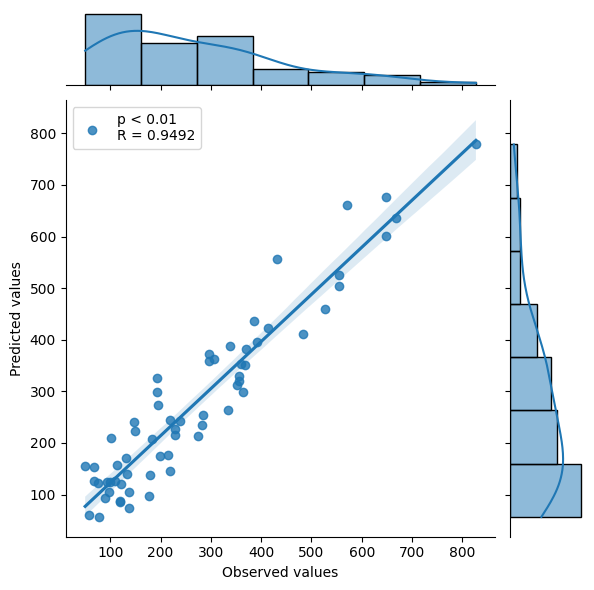

In [14]:
plt.figure(figsize=(15,15))
sns.jointplot(
    x=df_maior_erro.columns[col1_obt],
    y=df_maior_erro.columns[col2_prev],
    kind='reg',
    data=df_maior_erro#[df_maior_erro['Lista observado'] > 300]
)

if pear_pos_maior_erro[1] < 0.01:
  plt.legend(['p < ' + '0.01' + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e relse:
else:
  plt.legend(['p = ' + str(round(pear_pos_maior_erro[1],4)) + '\nR = ' + str(round(pear_pos_maior_erro[0], 4))]) #calculando p e r

#Predição do modelo

In [15]:
predictions = modelo_maior_erro.predict(X_test_maior_erro)

2/2 [==============================] - 1s 244ms/step


In [16]:
# Compara as previsões com os valores reais
for i in range(len(predictions)):
    print(f"Valor real: {y_test_maior_erro[i]}, Valor predito: {predictions[i]}")

Valor real: 483, Valor predito: [411.92657]
Valor real: 195, Valor predito: [274.3598]
Valor real: 285, Valor predito: [254.90332]
Valor real: 275, Valor predito: [213.09683]
Valor real: 648, Valor predito: [601.37445]
Valor real: 198, Valor predito: [174.20956]
Valor real: 827, Valor predito: [778.58594]
Valor real: 297, Valor predito: [359.62344]
Valor real: 367, Valor predito: [350.65872]
Valor real: 391, Valor predito: [396.4804]
Valor real: 306, Valor predito: [363.63092]
Valor real: 134, Valor predito: [140.72401]
Valor real: 218, Valor predito: [244.28851]
Valor real: 648, Valor predito: [676.9187]
Valor real: 282, Valor predito: [234.72577]
Valor real: 571, Valor predito: [661.7517]
Valor real: 297, Valor predito: [372.11044]
Valor real: 89, Valor predito: [93.218414]
Valor real: 218, Valor predito: [146.01047]
Valor real: 668, Valor predito: [635.4006]
Valor real: 526, Valor predito: [459.0748]
Valor real: 67, Valor predito: [126.86943]
Valor real: 229, Valor predito: [227.061

#Predição de Frequência Absoluta

In [17]:
df_maior_erro


,Observed values,Predicted values,Lista preditos
0,483,411.93,411.926575
1,195,274.36,274.359802
2,285,254.90,254.903320
3,275,213.10,213.096832
4,648,601.37,601.374451
...,...,...,...
58,121,119.75,119.752411
59,77,56.70,56.697132
60,120,86.25,86.253975
61,120,88.00,88.004112


In [18]:
df_maior_erro['Diferença'] = df_maior_erro['Observed values'] - df_maior_erro['Predicted values']

In [19]:
df_maior_erro

,Observed values,Predicted values,Lista preditos,Diferença
0,483,411.93,411.926575,71.07
1,195,274.36,274.359802,-79.36
2,285,254.90,254.903320,30.10
3,275,213.10,213.096832,61.90
4,648,601.37,601.374451,46.63
...,...,...,...,...
58,121,119.75,119.752411,1.25
59,77,56.70,56.697132,20.30
60,120,86.25,86.253975,33.75
61,120,88.00,88.004112,32.00


In [20]:
import matplotlib.pyplot as plt

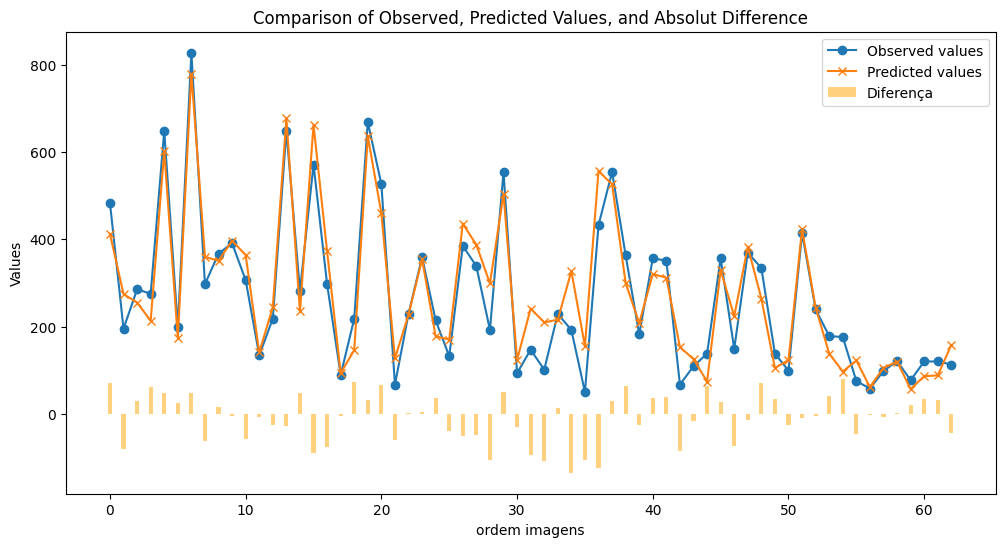

In [21]:
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença
plt.bar(df_maior_erro.index, df_maior_erro['Diferença'], width=0.3, alpha=0.5, label='Diferença', color='orange')

# Adiciona rótulos e título
plt.xlabel('ordem imagens')
plt.ylabel('Values')
plt.title('Comparison of Observed, Predicted Values, and Absolut Difference')
plt.legend()

# Mostra o gráfico
plt.show()

**Interpretação**:
* No gráfico, você pode ver que as linhas de "Observed Values" e "Predicted Values" estão bastante próximas na maioria dos pontos, o que indica que o modelo está realizando previsões com boa precisão.
* No entanto, existem algumas discrepâncias visíveis, evidenciadas pelas barras de "Difference". As barras amarelas variam em magnitude e sinal, mostrando onde e em que medida o modelo errou.
* Quando as barras estão próximas de zero, o modelo fez previsões muito próximas dos valores reais. Já nas áreas onde as barras são mais altas ou baixas, as previsões do modelo se distanciaram dos valores observados.

**Conclusão**:
Esse gráfico permite avaliar visualmente o desempenho do modelo de regressão. A proximidade das linhas de valores observados e preditos sugere que o modelo está funcionando bem, mas as barras de diferença ajudam a identificar onde ele comete erros e quão grandes são esses erros.

#Previsão Frequência Relativa (%)

In [22]:
#Calcula a diferença relativa entre o valor real e o valor predito (em %)
# df_maior_erro['Relative Difference (%)'] = ((df_maior_erro['Observed values'] - df_maior_erro['Predicted values']) / df_maior_erro['Observed values']) * 100
# df_maior_erro.head()

In [23]:
df_maior_erro['Relative Difference (%)'] = ((df_maior_erro['Predicted values']*100) / df_maior_erro['Observed values'])
df_maior_erro.head()

,Observed values,Predicted values,Lista preditos,Diferença,Relative Difference (%)
0,483,411.93,411.926575,71.07,85.285714
1,195,274.36,274.359802,-79.36,140.697436
2,285,254.90,254.903320,30.10,89.438596
3,275,213.10,213.096832,61.90,77.490909
4,648,601.37,601.374451,46.63,92.804012


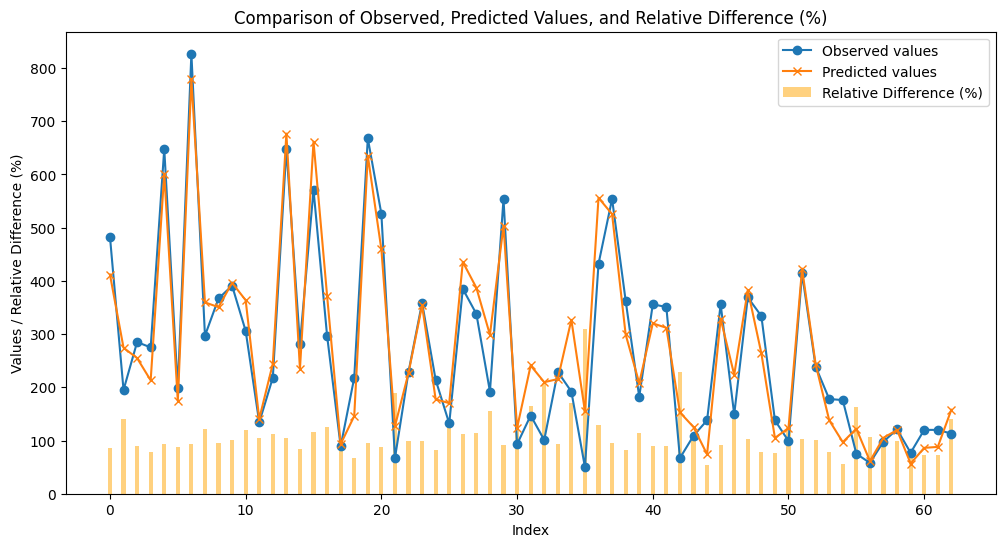

In [24]:
# Cria o gráfico comparando os valores
plt.figure(figsize=(12, 6))

# Plotando os valores observados e preditos
plt.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o')
plt.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x')

# Adiciona a linha da diferença relativa
plt.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=0.3, alpha=0.5, label='Relative Difference (%)', color='orange')

# Adiciona rótulos e título
plt.xlabel('Index')
plt.ylabel('Values / Relative Difference (%)')
plt.title('Comparison of Observed, Predicted Values, and Relative Difference (%)')
plt.legend()

# Mostra o gráfico
plt.show()

**Explicação**:
1. Diferença Relativa: A diferença relativa é calculada dividindo a diferença absoluta pelo valor observado e multiplicando por 100 para expressá-la como uma porcentagem.
2. Gráfico de Barras para Diferença Relativa: As barras agora representam a diferença em termos percentuais (%), mostrando onde o modelo previu valores maiores ou menores em relação aos valores reais.
3. Outros Detalhes: As linhas dos valores observados e preditos permanecem as mesmas para facilitar a comparação, mas o foco aqui está nas barras de diferença relativa.

**Interpretação**:
* Esse gráfico ajudará a visualizar melhor os erros em termos proporcionais, o que é útil especialmente quando os valores observados variam bastante. A análise de erro em termos percentuais permite ver onde o modelo está errando mais, independentemente da magnitude dos valores absolutos.

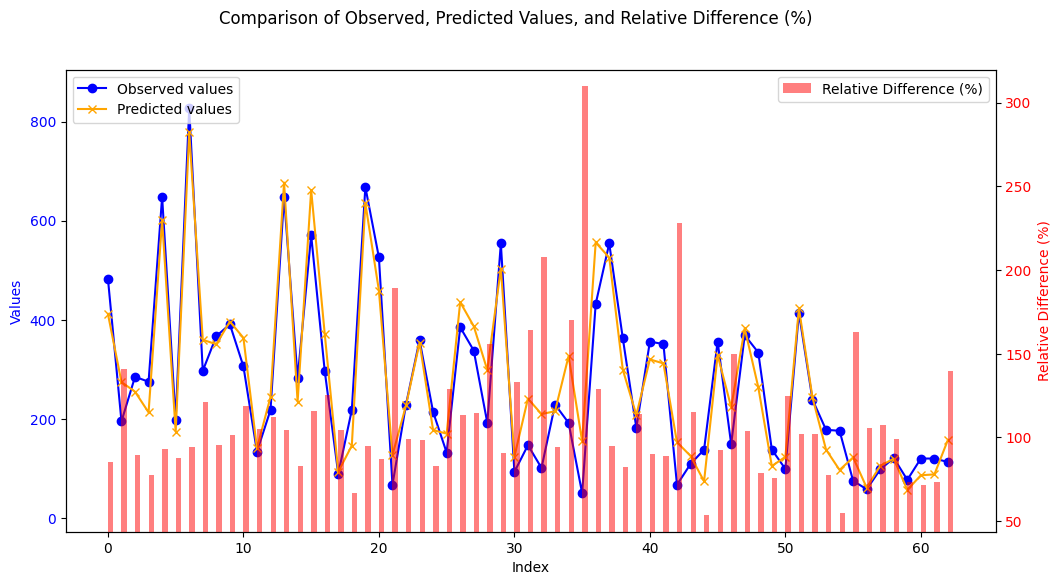

In [25]:
# Cria o gráfico com dois eixos Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo Y da esquerda (para valores observados e preditos)
ax1.set_xlabel('Index')
ax1.set_ylabel('Values', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x', color='orange')
ax1.tick_params(axis='y', labelcolor='blue')

# Ajusta o limite do eixo Y da esquerda para aumentar a escala
y_min = df_maior_erro[['Observed values', 'Predicted values']].min().min()
y_max = df_maior_erro[['Observed values', 'Predicted values']].max().max()
ax1.set_ylim([y_min - 0.1 * (y_max - y_min), y_max + 0.1 * (y_max - y_min)])

# Adiciona o segundo eixo Y à direita (para diferença relativa)
ax2 = ax1.twinx()
ax2.set_ylabel('Relative Difference (%)', color='red')
# Ajusta a largura das barras
bar_width = 0.4
ax2.bar(df_maior_erro.index + bar_width / 2, df_maior_erro['Relative Difference (%)'], width=bar_width, alpha=0.5, label='Relative Difference (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')


# Ajusta o limite do eixo Y da direita para melhor visualização das barras
ax2.set_ylim([df_maior_erro['Relative Difference (%)'].min() - 10,
              df_maior_erro['Relative Difference (%)'].max() + 10])

# Títulos e legendas
fig.suptitle('Comparison of Observed, Predicted Values, and Relative Difference (%)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Mostra o gráfico
plt.show()

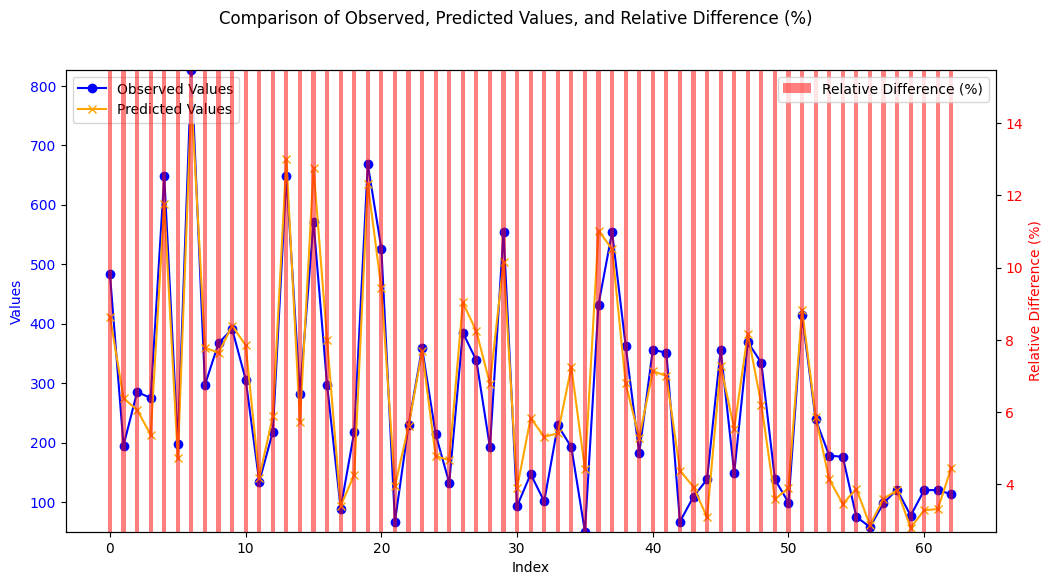

In [26]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo Y da esquerda (para valores observados e preditos)
ax1.set_xlabel('Index')
ax1.set_ylabel('Values', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed Values', marker='o', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted Values', marker='x', color='orange')
ax1.tick_params(axis='y', labelcolor='blue')

# Mantém a escala normal do eixo Y da esquerda
ax1.set_ylim(df_maior_erro[['Observed values', 'Predicted values']].min().min(),
             df_maior_erro[['Observed values', 'Predicted values']].max().max())

# Adiciona o segundo eixo Y à direita (para diferença relativa)
ax2 = ax1.twinx()
ax2.set_ylabel('Relative Difference (%)', color='red')

# Ajusta a largura das barras e reduz bastante a altura das barras
bar_width = 0.3
ax2.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=bar_width, alpha=0.5, label='Relative Difference (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Diminui bastante a altura das barras do eixo direito ajustando a escala
ax2.set_ylim(df_maior_erro['Relative Difference (%)'].min() * 0.05, df_maior_erro['Relative Difference (%)'].max() * 0.05)  # Reduz em 95%

# Títulos e legendas
fig.suptitle('Comparison of Observed, Predicted Values, and Relative Difference (%)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Mostra o gráfico
plt.show()

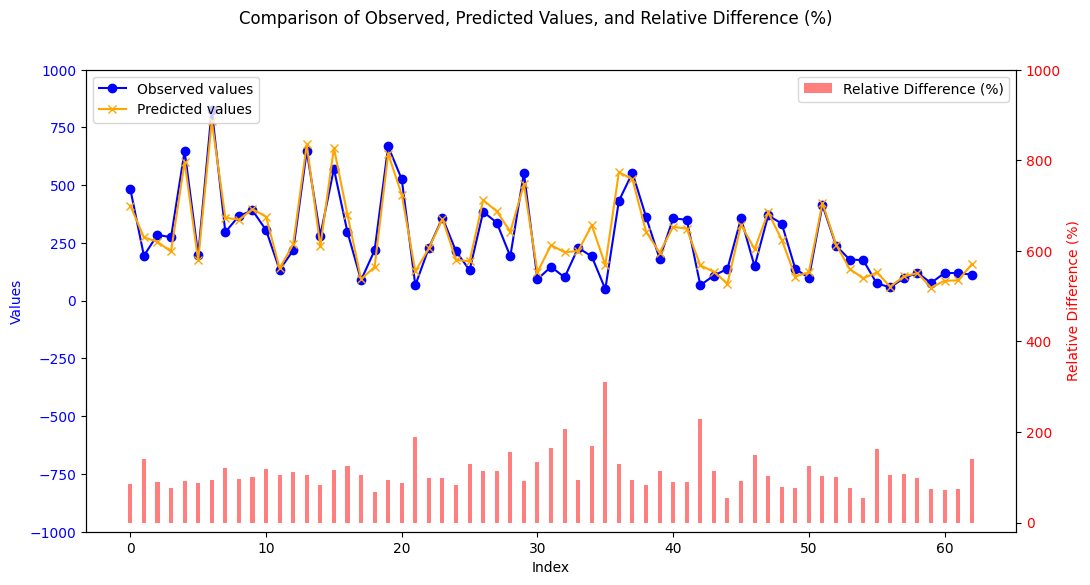

In [27]:
# Cria o gráfico com dois eixos Y
fig, ax1 = plt.subplots(figsize=(12, 6))

# Eixo Y da esquerda (para valores observados e preditos)
ax1.set_xlabel('Index')
ax1.set_ylabel('Values', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Observed values'], label='Observed values', marker='o', color='blue')
ax1.plot(df_maior_erro.index, df_maior_erro['Predicted values'], label='Predicted values', marker='x', color='orange')
ax1.tick_params(axis='y', labelcolor='blue')

# Mantém a escala normal do eixo Y da esquerda
# ax1.set_ylim(df_maior_erro[['Observed values', 'Predicted values']].min().min(),
#              df_maior_erro[['Observed values', 'Predicted values']].max().max())
ax1.set_ylim(-1000, 1000)

# Adiciona o segundo eixo Y à direita (para diferença relativa)
ax2 = ax1.twinx()
ax2.set_ylabel('Relative Difference (%)', color='red')


# Ajusta a largura das barras
bar_width = 0.3
ax2.bar(df_maior_erro.index, df_maior_erro['Relative Difference (%)'], width=bar_width, alpha=0.5, label='Relative Difference (%)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Corrige a amplitude do eixo Y da direita para -15 a 300
ax2.set_ylim(-20, 1000)

# Títulos e legendas
fig.suptitle('Comparison of Observed, Predicted Values, and Relative Difference (%)')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Mostra o gráfico
plt.show()